# An Interpreter for a Simple Programming Language

In this notebook we develop an interpreter for a small programming language.  We will utilize the parser generator
`Larkita` to define our language rules.  The parser generated by `Larkita` returns the abstract syntax tree of a
program as a nested tuple, so we do not have to convert a parse tree.  Nested tuples are values of the type
`nested` (see `../Chapter-07/01-Calculator.ipynb`):  for example, the tuple `("while", test, body)` is the value
`Node [Leaf (Str "while"); test; body]`.

In [1]:
#use "../lib/nb.ml";;
load_lib "larkita.ml"

- : unit = ()
Findlib has been successfully loaded. Additional directives:
  #require "package";;      to load a package
  #list;;                   to list the available packages
  #camlp4o;;                to load camlp4 (standard syntax)
  #camlp4r;;                to load camlp4 (revised syntax)
  #predicates "p,q,...";;   to set these predicates
  Topfind.reset();;         to force that packages will be reloaded
  #thread;;                 to enable threads

- : unit = ()
- : unit = ()
val lib_dir : string = "../lib"
val loaded_libs : (string, unit) Hashtbl.t = <abstr>
val load_lib : string -> unit = <fun>


- : unit = ()


## Specification of the Grammar

Below is the grammar for our simple `C`-like language, written in *Extended Backus-Naur Form* (EBNF).  It is stored
in the file `sl.lark`.

Our programming language allows both single-line (`//`) and multi-line (`/* */`) comments.  We instruct the parser
to entirely `%ignore` them alongside standard whitespace.

The grammar also determines the abstract syntax tree:  The string literals of an alternative form the *head* of the
tuple that is returned for this alternative, while all other symbols become its *children*.

* In contrast to `C`, the body of an `if` statement or a `while` loop always has to be enclosed in braces, even if
  it consists of a single statement.  Therefore, the body is a `program`, i.e. a sequence of statements.
* The directive `%ignore: "(", ")", "{", "}", ";"` (note the colon) removes the parentheses, the braces, and the
  semicolon from the heads of *all* alternatives, since these literals carry no information.  Hence the alternative
    ```
       "while" "(" bool_expr ")" "{" program "}"
    ```
  yields the tuple
  ```
       ("while", test, body)
  ```
  where `body` is the tuple
  `("program", stmnt, ...)` of the statements in braces, and the alternative
  `ID ":=" expr ";"` yields `(":=", ("ID", name), expr)`.
* An *inner alternative* like `("+" | "-")` abbreviates several alternatives:  The alternative
  `expr ("+" | "-") product` stands for the two alternatives `expr "+" product` and `expr "-" product`.  Hence the
  operator that has been read is the head, e.g. `x - 1` yields `("-", ("ID", "x"), ("INT", "1"))`.
* An alternative that consists of a single symbol passes the abstract syntax tree of this symbol through.  Hence a
  parenthesized expression is the expression inside.
* An *alias* `-> name` replaces the head.  Without the alias, the alternative `expr ";"` would consist of a single
  symbol and would therefore return the expression itself.  With the alias, it yields `("expr", expr)`.
* The arguments of a function call are written inline as `[expr ("," expr)*]`.  The children of an optional part and
  of a repetition are spliced into the tuple of the alternative, so a function call yields
  `("call", ("ID", name), arg_1, ..., arg_n)`.
* The program is the first rule of the grammar and therefore its start symbol.  As the alternative `stmnt*` contains
  no literal, the name of the rule is used as head:  A program yields the tuple `("program", stmnt_1, ..., stmnt_n)`.

In [2]:
cat "sl.lark"

program: stmnt*

stmnt: "if"    "(" bool_expr ")" "{" program "}"
     | "while" "(" bool_expr ")" "{" program "}"
     | ID ":=" expr ";"
     | expr ";"                                 -> "expr"

bool_expr: expr ("==" | "!=" | "<=" | ">=" | "<" | ">") expr

expr: expr ("+" | "-") product
    | product

product: product ("*" | "/" | "%") factor
       | factor

factor: "(" expr ")"
      | INT
      | ID
      | ID "(" [expr ("," expr)*] ")" -> "call"

// These literals are left out of the heads of all tuples.
%ignore: "(", ")", "{", "}", ";"

// Lexical definitions
%import common.CNAME -> ID, common.INT, common.WS

// In order to show how it's done, I have defined the tokens
// CPP_COMMENT and C_COMMENT describing comments myself.
CPP_COMMENT: /\/\/[^\n]*/
C_COMMENT:   "/*" /(.|\n)*?/ "*/"

// Ignore whitespace and comments
%ignore WS, C_COMMENT, CPP_COMMENT


- : unit = ()


We generate the parser.  `Larkita` always generates a *canonical LR(1) parser*.  A description of the states of the
LR(1) automaton is written into the file `sl.out`.

In [19]:
let parser = Larkita.open_ ~out_file:"sl.out" "sl.lark"

val parser : Larkita.t = <parser "sl.lark", start "program">


Let us check that `Larkita` was able to generate a parser.

In [20]:
let report = read_file "sl.out" in
let rec find i = if String.sub report i 7 = "States\n" then i else find (i + 1) in
print_string (String.sub report 0 (find 0));
flush stdout

Canonical LR(1) automaton generated by Larkita

Grammar:      sl.lark
Start symbol: program
States:       157
Conflicts:    0 (0 unresolved)


Rules
=====

Every rule is followed by the abstract syntax tree that a reduction produces.
"*name" stands for the list of children collected by the auxiliary rule "name".
"text" stands for the text of a named token.

  (0)   $root_program → program
  (1)   program → __program_star_0                         ⇒ ("program", *__program_star_0)
  (2)   program → ε                                        ⇒ ("program",)
  (3)   stmnt → "if" "(" bool_expr ")" "{" program "}"     ⇒ ("if", ast(bool_expr), ast(program))
  (4)   stmnt → "while" "(" bool_expr ")" "{" program "}"  ⇒ ("while", ast(bool_expr), ast(program))
  (5)   stmnt → ID ":=" expr ";"                           ⇒ (":=", ("ID", text), ast(expr))
  (6)   stmnt → expr ";"                                   ⇒ ("expr", ast(expr))
  (7)   bool_expr → expr "==" expr                         ⇒ ("==", a

- : unit = ()


## The Abstract Syntax Tree

The parser returns the abstract syntax tree as a nested tuple.  This tuple has exactly the structure that is needed
by our evaluation and visualization functions.  The shapes that are produced are the following:

| construct              | nested tuple                                       |
|:-----------------------|:---------------------------------------------------|
| program, body          | `("program", stmnt, ...)`                          |
| assignment             | `(":=", ("ID", name), expr)`                       |
| expression statement   | `("expr", expr)`                                   |
| conditional, loop      | `("if", test, body)`, `("while", test, body)`      |
| binary operator        | `(op, lhs, rhs)`, for example `("+", lhs, rhs)`    |
| number                 | `("INT", digits)`                                  |
| variable               | `("ID", name)`                                     |
| function call          | `("call", ("ID", name), arg, ...)`                 |

As an OCaml value, the tuple `(op, lhs, rhs)` is `Node [Leaf (Str op); lhs; rhs]` and the token `("ID", name)` is
`Node [Leaf (Str "ID"); Leaf (Str name)]`.

For example, the statement `x := 1 + 2 * y;` yields the following tuple:

In [21]:
Larkita.parse parser "x := 1 + 2 * y;"

- : nested =
("program", (":=", ("ID", "x"), ("+", ("INT", "1"), ("*", ("INT", "2"), ("ID", "y")))))


The external helper file `AST2Dot.ipynb` is used to represent our generated nested tuple ADT graphically.

In [22]:
run_notebook "AST2Dot.ipynb"

- : unit = ()


The values that are stored in the variables of our programs are numbers of the type `value` from
`../lib/nested.ml`:  `Int n` is an integer and `Float x` is a floating point number.  The operator `/` always
yields a floating point number, while `+`, `-`, `*`, and `%` yield an integer if both arguments are integers.
The functions `floor_mod` and `floor_fmod` compute the remainder of a division that rounds down, so that the
remainder has the sign of the divisor.

In [23]:
let to_float (n : value) : float =
  match n with
  | Int k -> float_of_int k
  | Float x -> x
  | _ -> invalid_arg "to_float: not a number"

let arith (int_op : int -> int -> int) (float_op : float -> float -> float) (a : value) (b : value) : value =
  match a, b with
  | Int x, Int y -> Int (int_op x y)
  | _ -> Float (float_op (to_float a) (to_float b))

let floor_mod (x : int) (y : int) : int = ((x mod y) + y) mod y

let floor_fmod (x : float) (y : float) : float = x -. y *. Float.floor (x /. y)

let num_to_string (n : value) : string =
  match n with
  | Float x -> float_repr x
  | _ -> Nested.value_to_string n

val to_float : value -> float = <fun>


val arith :
  (int -> int -> int) -> (float -> float -> float) -> value -> value -> value =
  <fun>


val floor_mod : int -> int -> int = <fun>


val floor_fmod : float -> float -> float = <fun>


val num_to_string : value -> string = <fun>


The function `parse` takes a `file_name` as its sole argument.  The file is read, parsed into a nested tuple, and
visualized via `graphviz`.

In [24]:
let parse (file_name : string) : Graphviz.t =
  let program = read_file file_name in
  print_endline program;
  let ast = Larkita.parse parser program in
  print_endline (Nested.to_string ast);
  tuple2dot ast

val parse : string -> Graphviz.t = <fun>


n := read();
s := 0;
i := 0;
while (i < n * n) {
    i := i + 1;
    s := s + i;
}
print(s);

("program", (":=", ("ID", "n"), ("call", ("ID", "read"))), (":=", ("ID", "s"), ("INT", "0")), (":=", ("ID", "i"), ("INT", "0")), ("while", ("<", ("ID", "i"), ("*", ("ID", "n"), ("ID", "n"))), ("program", (":=", ("ID", "i"), ("+", ("ID", "i"), ("INT", "1"))), (":=", ("ID", "s"), ("+", ("ID", "s"), ("ID", "i"))))), ("expr", ("call", ("ID", "print"), ("ID", "s"))))


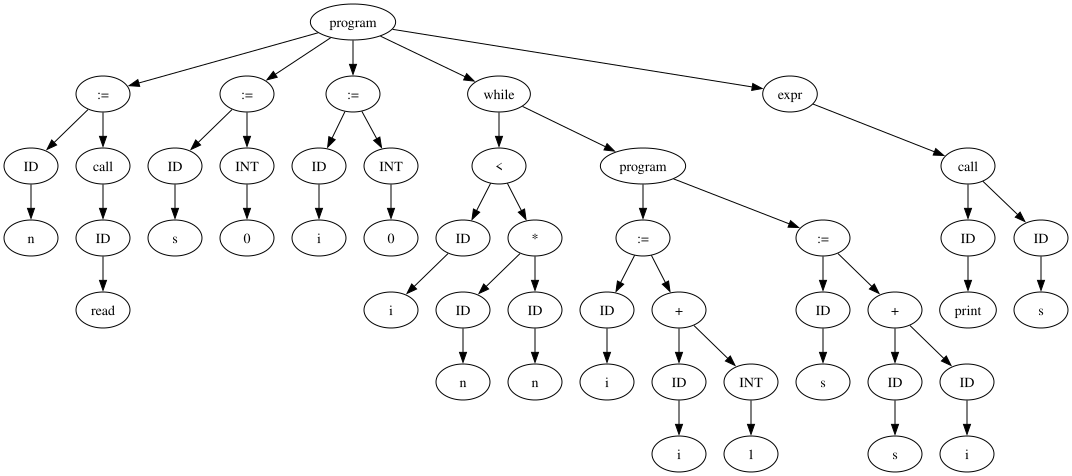

- : unit = ()


In [25]:
Graphviz.display (parse "sum.sl")

The function `execute_tuple` loops through statements linearly. The hash table `values` is the continuous state that gets updated as assignments occur.

The functions `execute_tuple`, `execute`, `evaluate_bool`, and `evaluate` call each other.  Since every function is
defined in its own cell, the next cell uses *forward references*:  `!execute_ref` is the function that is currently
stored in the box `execute_ref`, and the box is filled once the function has been defined.  The variable `values`
is a hash table, i.e. a mutable dictionary.

In [26]:
let not_yet_defined _ = failwith "not yet defined"

type env = (string, value) Hashtbl.t

let execute_ref       : (nested -> env -> unit) ref   = ref not_yet_defined
let evaluate_bool_ref : (nested -> env -> bool) ref   = ref not_yet_defined
let evaluate_ref      : (nested -> env -> value) ref = ref not_yet_defined

let execute_tuple (statementList : nested list) (values : env) : unit =
  List.iter (fun stmnt -> !execute_ref stmnt values) statementList

val not_yet_defined : 'a -> 'b = <fun>


type env = (string, value) Hashtbl.t


val execute_ref : (nested -> env -> unit) ref = {contents = <fun>}


val evaluate_bool_ref : (nested -> env -> bool) ref = {contents = <fun>}


val evaluate_ref : (nested -> env -> value) ref = {contents = <fun>}


val execute_tuple : nested list -> env -> unit = <fun>


The function `execute` matches recursively against the shape of the nested tuple statement node, triggering evaluation or recursive execution sequences.

In [11]:
let rec execute (stmnt : nested) (values : env) : unit =
  match stmnt with
  | Node (Leaf (Str "program") :: sl) -> execute_tuple sl values
  | Node [ Leaf (Str ":="); Node [ Leaf (Str "ID"); Leaf (Str var) ]; value ] -> Hashtbl.replace values var (!evaluate_ref value values)
  | Node [ Leaf (Str "expr"); expr ] -> ignore (!evaluate_ref expr values)
  | Node [ Leaf (Str "if"); test; stmnt ] -> if !evaluate_bool_ref test values then execute stmnt values
  | Node [ Leaf (Str "while"); test; stmnt ] ->
      while !evaluate_bool_ref test values do
        execute stmnt values
      done
  | _ -> failwith (Nested.to_string stmnt ^ " unexpected")
;;
execute_ref := execute

val execute : nested -> env -> unit = <fun>


- : unit = ()


The function `evaluate_bool` executes conditional logical statements returning a pure boolean output.

In [28]:
let evaluate_bool (expr : nested) (values : env) : bool =
  let compare lhs rhs = Float.compare (to_float (!evaluate_ref lhs values)) (to_float (!evaluate_ref rhs values)) in
  match expr with
  | Node [ Leaf (Str "=="); lhs; rhs ] -> compare lhs rhs =  0
  | Node [ Leaf (Str "!="); lhs; rhs ] -> compare lhs rhs <> 0
  | Node [ Leaf (Str "<="); lhs; rhs ] -> compare lhs rhs <= 0
  | Node [ Leaf (Str ">="); lhs; rhs ] -> compare lhs rhs >= 0
  | Node [ Leaf (Str "<"); lhs; rhs ] -> compare lhs rhs <  0
  | Node [ Leaf (Str ">"); lhs; rhs ] -> compare lhs rhs >  0
  | _ -> failwith (Nested.to_string expr ^ " unexpected")
;;
evaluate_bool_ref := evaluate_bool

val evaluate_bool : nested -> env -> bool = <fun>


- : unit = ()


The function `evaluate` calculates specific numerical values given either primitives (numbers and variables, which
are represented as tokens) or compound arithmetic operations.  We use `match` to distinguish the shapes
of the nested tuples.

In [29]:
let rec evaluate (expr : nested) (values : env) : value =
  match expr with
  | Node [ Leaf (Str "INT"); Leaf (Str digits) ] -> Int (int_of_string digits)
  | Node [ Leaf (Str "ID"); Leaf (Str name) ] -> Hashtbl.find values name
  | Node [ Leaf (Str "call"); Node [ Leaf (Str "ID"); Leaf (Str "read") ] ] -> Int (int_of_string (input "Please enter a natural number: "))
  | Node [ Leaf (Str "call"); Node [ Leaf (Str "ID"); Leaf (Str "print") ]; expr ] ->
      print_endline (num_to_string (evaluate expr values));
      Int 0
  | Node [ Leaf (Str "+"); lhs; rhs ] -> arith ( + ) ( +. ) (evaluate lhs values) (evaluate rhs values)
  | Node [ Leaf (Str "-"); lhs; rhs ] -> arith ( - ) ( -. ) (evaluate lhs values) (evaluate rhs values)
  | Node [ Leaf (Str "*"); lhs; rhs ] -> arith ( * ) ( *. ) (evaluate lhs values) (evaluate rhs values)
  | Node [ Leaf (Str "/"); lhs; rhs ] -> Float (to_float (evaluate lhs values) /. to_float (evaluate rhs values))
  | Node [ Leaf (Str "%"); lhs; rhs ] -> arith floor_mod floor_fmod (evaluate lhs values) (evaluate rhs values)
  | _ -> failwith (Nested.to_string expr ^ " unexpected")
;;
evaluate_ref := evaluate

val evaluate : nested -> env -> value = <fun>


- : unit = ()


In [30]:
cat "sum.sl"

n := read();
s := 0;
i := 0;
while (i < n * n) {
    i := i + 1;
    s := s + i;
}
print(s);


- : unit = ()


Finally, we bring the whole pipeline together.  `main` will open the program file, parse it into a nested tuple, and
evaluate it under an isolated state dict.

In [31]:
let main (file : string) : unit =
  let program = read_file file in
  let ast = Larkita.parse parser program in
  Graphviz.display (tuple2dot ast);
  let values : env = Hashtbl.create 16 in
  execute ast values

val main : string -> unit = <fun>


- : unit = ()


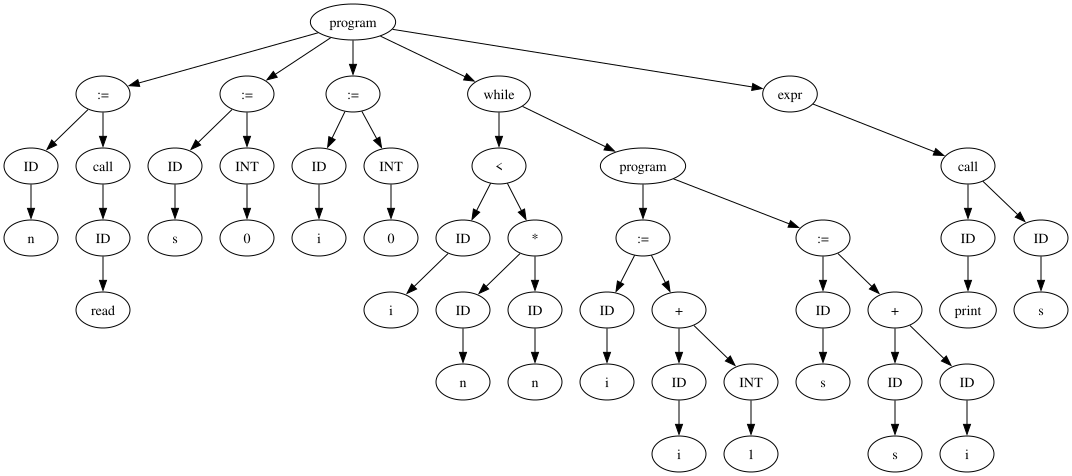

Please enter a natural number: 10
5050


- : unit = ()


In [32]:
simulate_input [ "10" ];;
main "sum.sl"

In [33]:
cat "factorial-while.sl"

f := 1;
i := 0;
n := read();
while (i < n) {
    i := i + 1;
    f := i * f;
}
print(f);



- : unit = ()


- : unit = ()


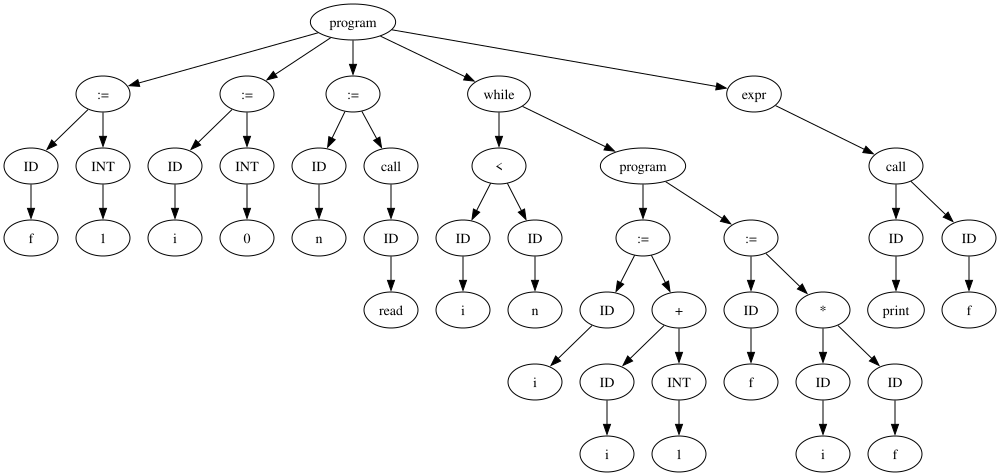

Please enter a natural number: 5
120


- : unit = ()


In [34]:
simulate_input [ "5" ];;
main "factorial-while.sl"